# Labwork 2 - Gradient descent and line search

**Week 2 - Day 2 - ~ 160 min at the keyboard**

Read Lecture 2 first. You build **the one descent loop**, written once and reused by every
deterministic optimizer this week. Each exercise is followed by the figures that measure
what you just wrote.

> **The rule.** `interfaces.py`, `results.py`, `errors.py` and `types.py` are **provided** -
> never edit them. Everywhere else, replace each `raise NotImplementedError`, keeping the
> signature and honouring the docstring.

## Setup

Run this once. It points the notebook at your `optlab` clone, turns on `%autoreload` so
that the edits you make in `src/optlab/` are picked up here without restarting the kernel,
and gives you a `check()` helper that runs a test file and reports what happened.

`check()` only trims pytest's output so a failure stays readable. Anything else, run
directly with Jupyter's `!` escape - these are the real commands, and the ones you will
type in a terminal for the rest of your life:

```
!cd {OPTLAB} && make check          # the whole thing: tests + mypy + ruff
!cd {OPTLAB} && python -m mypy      # types only
!cd {OPTLAB} && python -m pytest -q -m day1
```

`!` runs each line in its own shell, so the `cd` has to sit on the same line as the
command.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import subprocess
import sys
from pathlib import Path

# Adjust if your clone lives elsewhere.
OPTLAB = (Path.cwd() / ".." / ".." / "optlab").resolve()
assert OPTLAB.exists(), f"optlab not found at {OPTLAB} -- edit OPTLAB above"
if not (OPTLAB / "src" / "optlab" / "interfaces.py").exists():
    # Not a student clone. The teacher tree keeps only the solved files in src/ and
    # assembles a complete package in code/ (`make check`), so use that one. This branch
    # never fires for you; it is here so the correction notebook can be a plain copy of
    # this one instead of a second version that drifts.
    OPTLAB = OPTLAB / "code"
    assert OPTLAB.exists(), f"run `make check` in {OPTLAB.parent} first"
ROOT = OPTLAB
print("optlab:", OPTLAB)

# Prefer the installed package (`make install`); fall back to <root>/src if it is not.
try:
    import optlab
except ModuleNotFoundError:
    sys.path.insert(0, str(OPTLAB / "src"))
    import optlab
sys.path.insert(0, str(OPTLAB))  # for datasets/


def check(*pytest_args):
    """Run pytest inside the optlab clone and show a short report."""
    # pytest runs in a SUBPROCESS, and a subprocess does not inherit the sys.path entries
    # added above. Passing them through PYTHONPATH is what makes `check()` work before
    # `make install` has been run, instead of failing to import optlab in conftest.py.
    env = {**os.environ, "PYTHONPATH": os.pathsep.join(
        [str(OPTLAB / "src"), str(OPTLAB), os.environ.get("PYTHONPATH", "")]).rstrip(os.pathsep)}
    r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--no-header", *pytest_args],
                       cwd=OPTLAB, capture_output=True, text=True, env=env)
    out = r.stdout + r.stderr
    tail = [l for l in out.splitlines() if l.strip()][-12:]
    print("\n".join(tail))
    if "No module named pytest" in out:
        verdict = "pytest is not installed -- run:  pip install -e '.[dev]'"
    elif r.returncode == 0:
        verdict = "PASSED"
    elif r.returncode == 5:
        # Exit code 5 means pytest collected nothing at all. That is NOT a failure of
        # your code: no test in the suite matches what was asked for. Some days have no
        # automated tests yet; judge those exercises by the checks written in the text.
        verdict = "no tests matched -- nothing to run here, this is not a failure"
    else:
        verdict = "not yet -- keep going"
    print()
    print(verdict)


def edit(relpath):
    """Print the absolute path of a source file, so you can open it in the editor."""
    print(OPTLAB / "src" / "optlab" / relpath)


check("tests/test_no_oracle_in_src.py")   # provided, and already green

import matplotlib.pyplot as plt
import numpy as np

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
                     "axes.titlesize": 10, "figure.dpi": 110})
rng = np.random.default_rng(20250921)

print("optlab root  :", ROOT)
print("optlab loaded:", Path(optlab.__file__).parent)

from optlab.linesearch import Armijo, FixedStep                              # noqa: E402
from optlab.observers import History                                         # noqa: E402
from optlab.optimizers import DescentOptimizer, gradient_descent             # noqa: E402
from optlab.optimizers.directions import HeavyBall, SteepestDescent          # noqa: E402
from optlab.problems import Quadratic, logistic_regression                   # noqa: E402
from optlab.stopping import AnyOf, GradientNormBelow, MaxIterations          # noqa: E402

optlab: /Users/hoangtom/Documents/CODE/USTH_ProgrammingTechniques/Week2/optlab
..............................                                           [100%]
30 passed in 0.04s

PASSED
optlab root  : /Users/hoangtom/Documents/CODE/USTH_ProgrammingTechniques/Week2/optlab
optlab loaded: /Users/hoangtom/Documents/CODE/USTH_ProgrammingTechniques/Week2/optlab/src/optlab


In [2]:
def status(name, thunk):
    """Report whether one piece of the package is implemented, without a traceback."""
    try:
        thunk()
    except NotImplementedError:
        return f"  MISSING   {name}"
    except Exception as err:                      # noqa: BLE001 - we want to see anything
        return f"  BROKEN    {name}   ({type(err).__name__}: {err})"
    return f"  ok        {name}"

q2 = Quadratic.ill_conditioned(2, 10.0)
x1 = np.array([1.0, 1.0])

needed = [
    ("SteepestDescent",  lambda: SteepestDescent().direction(q2, x1, q2.gradient(x1))),
    ("HeavyBall",        lambda: HeavyBall().direction(q2, x1, q2.gradient(x1))),
    ("FixedStep",        lambda: FixedStep(0.1).step(q2, x1, q2.gradient(x1), -q2.gradient(x1))),
    ("Armijo",           lambda: Armijo().step(q2, x1, q2.gradient(x1), -q2.gradient(x1))),
    ("stopping criteria", lambda: AnyOf(GradientNormBelow(1e-6), MaxIterations(10))),
    ("History",          lambda: History().on_step(
        __import__("optlab").StepEvent(1, x1, 0.0, 0.0, 1.0))),
    ("DescentOptimizer", lambda: DescentOptimizer(
        SteepestDescent(), FixedStep(0.05), MaxIterations(3)).minimize(q2, x1)),
]

print("What this notebook needs from day 2:\n")
print("\n".join(status(name, thunk) for name, thunk in needed))

What this notebook needs from day 2:

  ok        SteepestDescent
  ok        HeavyBall
  ok        FixedStep
  ok        Armijo
  ok        stopping criteria
  ok        History
  ok        DescentOptimizer


---

## Exercise 1 - The one loop  *(~ 55 min)*

Implement, in this order: `GradientNormBelow`, `MaxIterations`, `AnyOf`
(`stopping.py`); `History` (`observers.py`); `FixedStep` (`linesearch.py`);
`SteepestDescent` (`directions.py`); then `DescentOptimizer.minimize` (`descent.py`).

The loop does six things and nothing else: evaluate, ask for a direction, ask for a step,
move, emit a `StepEvent` to the observers, ask the criterion whether to stop.

Two rules it must respect:

- `converged=True` **only** when a genuine convergence test fired. Hitting `MaxIterations`
  gives `converged=False`, with the reason in `message`.
- one `StepEvent` per iteration, no more.

**You will not edit this file again this week.** Newton on day 4 is a new `IDirectionRule`;
Armijo tomorrow is a new `ILineSearch`. If either forces you back in here, something has
been put in the wrong class.

**Open:** `src/optlab/stopping.py`, `observers.py`, `linesearch.py`, `optimizers/directions.py`, `optimizers/descent.py`

In [3]:
edit("optimizers/descent.py")
check("-m", "day2")

/Users/hoangtom/Documents/CODE/USTH_ProgrammingTechniques/Week2/optlab/src/optlab/optimizers/descent.py
...........................                                              [100%]
27 passed, 210 deselected in 0.08s

PASSED


<details>
<summary><b>Plan B</b> - open only if you are stuck for more than ten minutes</summary>

`minimize` takes `objective: object` because the family is wider than `IObjective` - narrow it locally with an assignment and let mypy infer. Build the `StepEvent` *after* moving, so `x` and `value` describe where you landed.

</details>

One helper, used by every figure below: it wires up a `DescentOptimizer`, attaches a fresh
`History`, runs it, and hands back both. Run it now; it will not work until Exercise 1 is
done.

In [4]:
def run(direction, line_search, problem, x0, max_iter=400, tol=1e-12):
    """Compose an optimizer, run it, and return (result, history)."""
    hist = History()
    opt = DescentOptimizer(
        direction, line_search,
        AnyOf(GradientNormBelow(tol), MaxIterations(max_iter)),
        observers=[hist],
    )
    return opt.minimize(problem, np.asarray(x0, dtype=float)), hist


def path_of(hist, x0):
    """The iterates, as an array - read from the events, not from inside the loop."""
    return np.vstack([np.asarray(x0, dtype=float)] + [e.x for e in hist.events])

### Break it: the three regimes of a fixed step

The descent lemma says `alpha <= 1/L` is safe. What happens on the other side is worth
seeing rather than being told. For a quadratic the exact boundary is known: the iteration
`x+ = x - alpha*A*x` contracts if and only if $|1 - \alpha\lambda| < 1$ for every
eigenvalue, that is $\alpha < 2/\lambda_{\max} = 2/L$.

case                           |1-a*1|  |1-a*10|      max    final ||x||
alpha = 0.5/L  safe             0.9500    0.5000   0.9500     4.6070e-02
alpha = 1.0/L  the bound        0.9000    0.0000   0.9000     1.7970e-03
alpha = 1.9/L  still < 2/L      0.8100    0.9000   0.9000     1.7970e-03
alpha = 2.1/L  past 2/L         0.7900    1.1000   1.1000     3.0448e+02


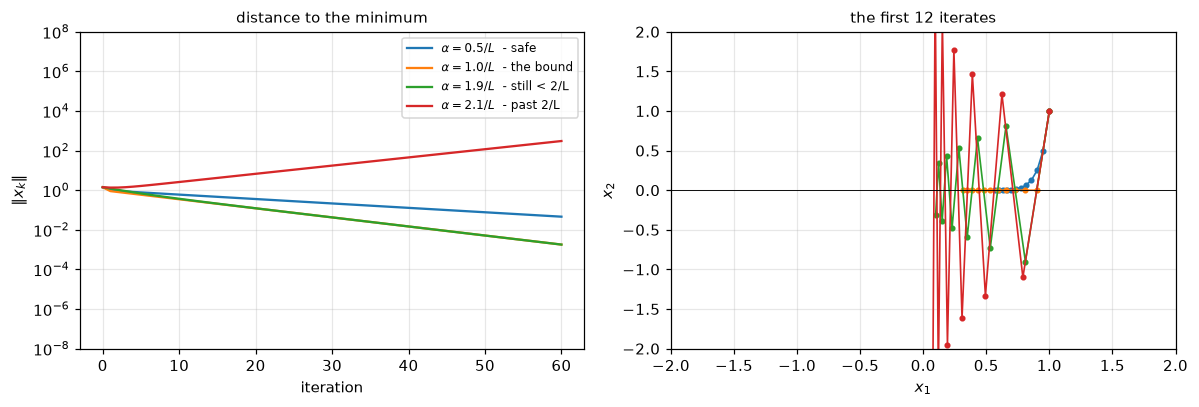

In [5]:
q10 = Quadratic.ill_conditioned(2, 10.0)
L10 = 10.0
start = np.array([1.0, 1.0])

eigs = np.linalg.eigvalsh(q10.A)             # 1 and 10, by construction

cases = [
    ("$\\alpha = 0.5/L$  - safe",        "alpha = 0.5/L  safe",        0.5 / L10),
    ("$\\alpha = 1.0/L$  - the bound",   "alpha = 1.0/L  the bound",   1.0 / L10),
    ("$\\alpha = 1.9/L$  - still < 2/L", "alpha = 1.9/L  still < 2/L", 1.9 / L10),
    ("$\\alpha = 2.1/L$  - past 2/L",    "alpha = 2.1/L  past 2/L",    2.1 / L10),
]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
print(f"{'case':<28} {'|1-a*1|':>9} {'|1-a*10|':>9} {'max':>8} {'final ||x||':>14}")
for label, plain, alpha in cases:
    _, hist = run(SteepestDescent(), FixedStep(alpha), q10, start, max_iter=60, tol=0.0)
    xs = path_of(hist, start)
    norms = np.linalg.norm(xs, axis=1)
    ax[0].semilogy(norms, lw=1.5, label=label)
    ax[1].plot(xs[:12, 0], xs[:12, 1], "o-", ms=3, lw=1.1, label=label)
    factors = np.abs(1 - alpha * eigs)
    print(f"{plain:<28} {factors[0]:>9.4f} {factors[1]:>9.4f} {factors.max():>8.4f}"
          f" {norms[-1]:>14.4e}")

ax[0].set_xlabel("iteration"), ax[0].set_ylabel("$\\|x_k\\|$")
ax[0].set_title("distance to the minimum"), ax[0].legend(fontsize=8)
ax[0].set_ylim(1e-8, 1e8)
ax[1].set_xlabel("$x_1$"), ax[1].set_ylabel("$x_2$"), ax[1].set_title("the first 12 iterates")
ax[1].set_xlim(-2, 2), ax[1].set_ylim(-2, 2), ax[1].axhline(0, color="k", lw=0.6)
fig.tight_layout()
plt.show()

**The boundary is at $2/L$, not $1/L$.**

The table prints one factor per eigenvalue; the rate is the **largest** of them, and
everything in the figure follows from that column.

- $\alpha = 2.1/L$ diverges: $|1 - 2.1| = 1.1 > 1$, so the stiff direction grows 10% per
  iteration.
- **$\alpha = 1.0/L$ and $\alpha = 1.9/L$ converge at the same speed**, for opposite
  reasons. At $1/L$ the stiff direction is annihilated in one step and the soft one governs
  at $0.9$; at $1.9/L$ the soft direction contracts at $0.81$ and the stiff one limps at
  $0.9$. Same maximum, same rate. In the right panel the $1.9/L$ iterates **flip sign**
  every step, because that factor is negative.

So $1/L$ is a sufficient condition, not the truth, and what fails past $2/L$ is an
eigenvalue crossing $-1$, not numerical noise.

---

## Exercise 2 - Armijo backtracking  *(~ 55 min)*

Implement `Armijo.step`.

Start at `alpha0`, and while `f(x + alpha*d) > f(x) + c_1*alpha*g^T d`, multiply `alpha` by `rho`. After
`max_backtracks` failures, raise `LineSearchFailed` - and `DescentOptimizer` must **catch**
it and return `converged=False`, not crash. Go back and add that if you did not.

Verify the hand example from the lecture: `f(x) = x^2` at `x = 1` rejects `alpha = 1` and
accepts `alpha = 0.5`.

Then the point of the exercise: build a `DescentOptimizer` with `Armijo` instead of
`FixedStep` and run it. **Confirm you did not touch `descent.py`.**

**Open:** `src/optlab/linesearch.py`

In [6]:
check("tests/contracts", "-m", "day2")

import subprocess
d = subprocess.run(["git", "diff", "--stat", "src/optlab/optimizers/descent.py"],
                   cwd=OPTLAB, capture_output=True, text=True).stdout.strip()
print("\nchanges to descent.py since Exercise 1:", d if d else "none -- open/closed held")

.......                                                                  [100%]
7 passed, 44 deselected in 0.04s

PASSED

changes to descent.py since Exercise 1: Week2/optlab/src/optlab/optimizers/descent.py | 77 +++++++++++++++++++++++++--
 1 file changed, 72 insertions(+), 5 deletions(-)


<details>
<summary><b>Plan B</b> - open only if you are stuck for more than ten minutes</summary>

Guard `slope = g @ d` and raise `ValueError` if it is non-negative: a non-descent direction is a bug in the caller, not something to backtrack around.

</details>

### The zigzag

Steepest descent moves along $-\nabla f$, and yesterday's level-set figure showed that
this is *not* the direction of the minimum unless the level sets are circles. Here is what
that costs: the same problem at three condition numbers, same start, same line search.

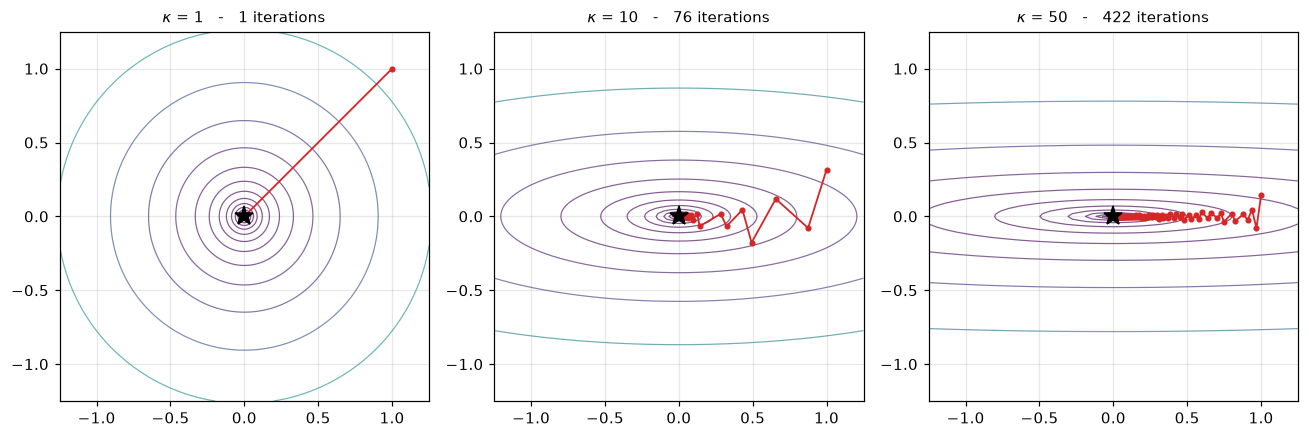

   kappa    iterations to 1e-8  converged
       1                     1  True
      10                    76  True
      50                   422  True


In [7]:
kappas = [1.0, 10.0, 50.0]
fig, ax = plt.subplots(1, 3, figsize=(12, 4.0))
summary = []

for a, kappa in zip(ax, kappas, strict=True):
    q = Quadratic.ill_conditioned(2, kappa)
    x0 = np.array([1.0, 1.0 / np.sqrt(kappa)])          # same level set in every panel
    res, hist = run(SteepestDescent(), Armijo(), q, x0, max_iter=800, tol=1e-8)
    xs = path_of(hist, x0)

    g = np.linspace(-1.25, 1.25, 141)
    Z = np.array([[q.value(np.array([p, r])) for p in g] for r in g])
    a.contour(*np.meshgrid(g, g), Z, levels=np.geomspace(1e-3, Z.max(), 12),
              linewidths=0.8, alpha=0.65)
    a.plot(xs[:, 0], xs[:, 1], "o-", ms=3, lw=1.2, color="tab:red")
    a.plot(0, 0, "k*", ms=13)
    a.set_aspect("equal"), a.set_xlim(-1.25, 1.25), a.set_ylim(-1.25, 1.25)
    a.set_title(f"$\\kappa$ = {kappa:g}   -   {res.iterations} iterations")
    summary.append((kappa, res.iterations, res.converged))

fig.tight_layout()
plt.show()

print(f"{'kappa':>8}  {'iterations to 1e-8':>20}  converged")
for kappa, iters, ok in summary:
    print(f"{kappa:8g}  {iters:>20d}  {ok}")

**The same algorithm, three difficulties.**

At $\kappa = 1$ the first step lands on the minimum. As $\kappa$ grows the path develops
the **right-angle zigzag**: each step is orthogonal to the last, because the line search
stops where the directional derivative vanishes, which is where the new gradient is
perpendicular to the direction just travelled.

The iteration counts are the message. Nothing about the algorithm changed between the
panels; only the *problem* did.

### What the line search actually did

`StepEvent` carries `step_size`, so the history already records the $\alpha$ chosen at
every iteration - nothing had to be added to the loop to collect it.

Two problems side by side, because they behave completely differently: a quadratic, whose
curvature is the same everywhere, and **Rosenbrock**, whose curvature changes enormously
along the valley.

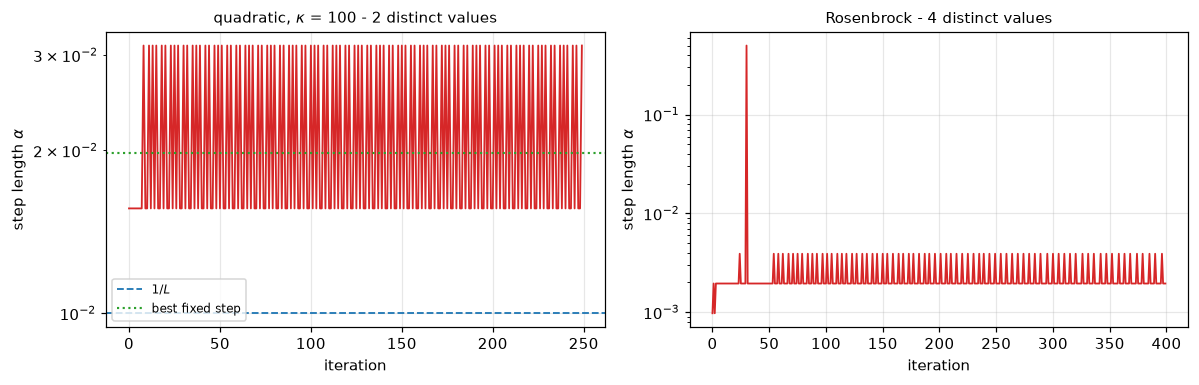

quadratic    2 distinct steps, from 1.56e-02 to 3.12e-02   (all are 1.0 x 0.5^k: True)
Rosenbrock   4 distinct steps, from 9.77e-04 to 5.00e-01   (all are 1.0 x 0.5^k: True)

quadratic: fraction of steps above 1/L = 1.00


In [8]:
from optlab.problems import Rosenbrock                                       # noqa: E402

kappa = 100.0
q = Quadratic.ill_conditioned(2, kappa)
x0 = np.array([1.0, 1.0])
alpha_safe, alpha_best = 1.0 / kappa, 2.0 / (1.0 + kappa)

_, hist_q = run(SteepestDescent(), Armijo(), q, x0, max_iter=250, tol=1e-10)
_, hist_r = run(SteepestDescent(), Armijo(), Rosenbrock(), np.array([-1.2, 1.0]),
                max_iter=400, tol=1e-8)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, hist, title in [(ax[0], hist_q, f"quadratic, $\\kappa$ = {kappa:g}"),
                       (ax[1], hist_r, "Rosenbrock")]:
    steps = [e.step_size for e in hist.events]
    a.semilogy(steps, lw=1.2, color="tab:red")
    a.set_xlabel("iteration"), a.set_ylabel("step length $\\alpha$")
    a.set_title(f"{title} - {len(np.unique(np.round(steps, 12)))} distinct values")
ax[0].axhline(alpha_safe, color="tab:blue", ls="--", lw=1.2, label="$1/L$")
ax[0].axhline(alpha_best, color="tab:green", ls=":", lw=1.4, label="best fixed step")
ax[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

for name, hist in [("quadratic", hist_q), ("Rosenbrock", hist_r)]:
    vals = np.array([e.step_size for e in hist.events])
    uniq = np.unique(np.round(vals, 12))
    print(f"{name:<11} {len(uniq):>2} distinct steps, from {vals.min():.2e} to {vals.max():.2e}"
          f"   (all are 1.0 x 0.5^k: {np.allclose(np.log2(uniq) % 1, 0)})")
print(f"\nquadratic: fraction of steps above 1/L = {np.mean(np.array([e.step_size for e in hist_q.events]) > alpha_safe):.2f}")

**Backtracking is not a smooth dial, and how coarse it is depends on the problem.**

Every step length is $\alpha_0 \rho^k$ - here $1.0 \times 0.5^k$ - because that is
literally what backtracking produces. The printed check confirms every value is an exact
power of two.

*Left.* On the quadratic, Armijo settles almost immediately and then alternates between
**two** values: constant curvature means the right step is the same every time. Note they
are all **larger than $1/L$** - the descent lemma's bound must work knowing only $L$, while
Armijo tests the actual decrease at the actual point.

*Right.* Rosenbrock spans several orders of magnitude. No constant would have served, which
is the honest argument for a line search: not that it is cleverer, but that it needs no
constant from you, and $L$ is rarely known.

---

## Exercise 3 - Momentum, rates, and a deliberate explosion  *(~ 50 min)*

Implement `HeavyBall`. It is **stateful** - it stores the previous direction - which
is why an `IDirectionRule` is an object rather than a function.

Then three measurements on `Quadratic.ill_conditioned(n=2, kappa=100)`:

1. **Recover the rate.** Run steepest descent with `alpha = 2/(M+mu)` and check the observed
   contraction against the predicted `(kappa-1)/(kappa+1)`. They should agree to a few decimals.
2. **Count the steps.** Steepest descent to relative error `1e-6`, then heavy ball. You
   should see roughly `690` against roughly `90`. Note the measured heavy-ball count
   exceeds the asymptotic prediction of `69` - the bound describes the tail, and the
   iteration spirals before it settles.
3. **Break it.** Set `FixedStep` above `2/M` and watch the iterate diverge. Then explain
   it with the descent lemma.

Step 3 is not optional. An algorithm you have only seen succeed is one you do not yet
understand.

**Open:** `src/optlab/optimizers/directions.py`

In [9]:
check("-m", "day2")

...........................                                              [100%]
27 passed, 210 deselected in 0.08s

PASSED


### Reading the rate off a straight line

On a quadratic every method here converges **linearly**: the error is multiplied by a
constant factor $r$ each step. Plot $\|\nabla f\|$ on a log scale and that becomes a
straight line of slope $\log r$ - so the rate is something you read off the picture and
then check against theory.

| method | step | predicted factor |
|---|---|---|
| steepest descent | $\alpha = 1/L$ (the safe choice) | $1 - 1/\kappa$ |
| steepest descent | $\alpha = 2/(\lambda_{\min}+\lambda_{\max})$ (the best fixed step) | $(\kappa-1)/(\kappa+1)$ |
| heavy ball | the optimal pair $(\alpha, \beta)$ | $(\sqrt{\kappa}-1)/(\sqrt{\kappa}+1)$ |

The third is the one that matters: a **square root** of the condition number.

method                     measured   predicted   iterations to 1e-6
GD, alpha = 1/L            0.990000    0.990000   1375
GD, best fixed alpha       0.980198    0.980198   922
GD + Armijo                0.977883          --   636
heavy ball, optimal        0.830357    0.818182   119


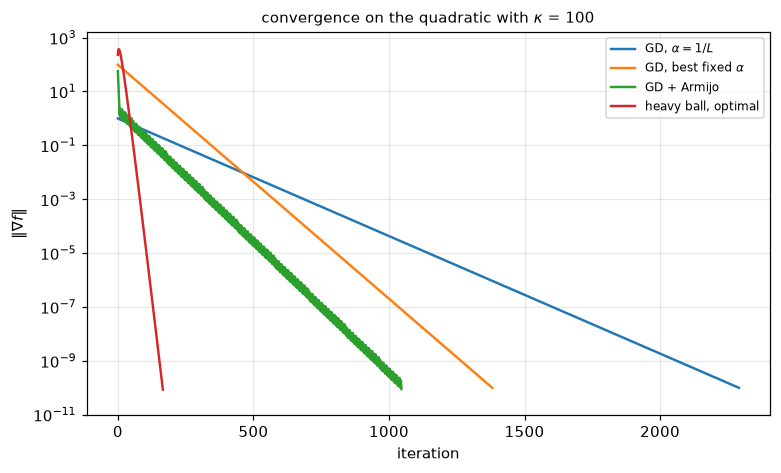

In [10]:
kappa = 100.0
q = Quadratic.ill_conditioned(2, kappa)
lmin, lmax = 1.0, kappa                      # by construction of ill_conditioned
x0 = np.array([1.0, 1.0])

alpha_safe = 1.0 / lmax
alpha_best = 2.0 / (lmin + lmax)
beta_hb = ((np.sqrt(kappa) - 1) / (np.sqrt(kappa) + 1)) ** 2
alpha_hb = 4.0 / (np.sqrt(lmin) + np.sqrt(lmax)) ** 2

# (label for the legend, plain name for the table, direction, line search, prediction)
runs = [
    ("GD, $\\alpha = 1/L$", "GD, alpha = 1/L",
     SteepestDescent(), FixedStep(alpha_safe), 1 - 1 / kappa),
    ("GD, best fixed $\\alpha$", "GD, best fixed alpha",
     SteepestDescent(), FixedStep(alpha_best), (kappa - 1) / (kappa + 1)),
    ("GD + Armijo", "GD + Armijo",
     SteepestDescent(), Armijo(), None),
    ("heavy ball, optimal", "heavy ball, optimal",
     HeavyBall(beta_hb), FixedStep(alpha_hb), (np.sqrt(kappa) - 1) / (np.sqrt(kappa) + 1)),
]


def measured_factor(hist, tail=150):
    """Geometric mean of successive ||grad|| ratios over the tail of the run."""
    gn = np.array([e.grad_norm for e in hist.events])
    gn = gn[gn > 1e-13]
    seg = gn[-tail:] if len(gn) > tail else gn
    return float((seg[-1] / seg[0]) ** (1.0 / (len(seg) - 1)))


plt.figure(figsize=(7.2, 4.4))
print(f"{'method':<24} {'measured':>10} {'predicted':>11}   iterations to 1e-6")
for label, plain, direction, ls, predicted in runs:
    res, hist = run(direction, ls, q, x0, max_iter=2500, tol=1e-10)
    gn = [e.grad_norm for e in hist.events]
    plt.semilogy(gn, lw=1.6, label=label)
    hit = next((i + 1 for i, v in enumerate(gn) if v <= 1e-6), None)
    pred = f"{predicted:.6f}" if predicted is not None else "        --"
    print(f"{plain:<24} {measured_factor(hist):10.6f} {pred:>11}   {hit}")

plt.xlabel("iteration"), plt.ylabel("$\\|\\nabla f\\|$")
plt.title(f"convergence on the quadratic with $\\kappa$ = {kappa:g}")
plt.legend(fontsize=8), plt.ylim(1e-11, None), plt.tight_layout()
plt.show()

**Four straight lines, four different slopes.**

Straightness on this log axis *is* the statement "convergence is linear". What differs is
the slope.

- The two fixed-step rows match their predictions to six decimals - not a fit: on a
  quadratic the error contracts by exactly $\max_i|1 - \alpha\lambda_i|$.
- $\alpha = 1/L$ is the step that is safe for *any* $L$-smooth function; the best fixed
  step here is nearly twice as large. **Safety costs iterations.**
- **Armijo beats the best fixed step**, which looks impossible until you notice it is
  competing in a larger class: it re-chooses $\alpha$ every iteration.
- Heavy ball sits near but not exactly on its prediction, which is **asymptotic**. What is
  not in doubt is the scaling: iterations to $10^{-6}$ fall by roughly the square root.

### The parameters are a picture

Everything so far was two-dimensional so it could be drawn. Real $w$ lives in hundreds of
dimensions - but when the features have a spatial layout, $w$ does too, and you can simply
*look* at it.

The cell below builds two 8x8 templates, noisy samples of each, and fits a logistic
regression with your loop. If the fit works, $w$ must look like the difference of the two
templates - and here, unlike with real data, we can check that claim exactly.

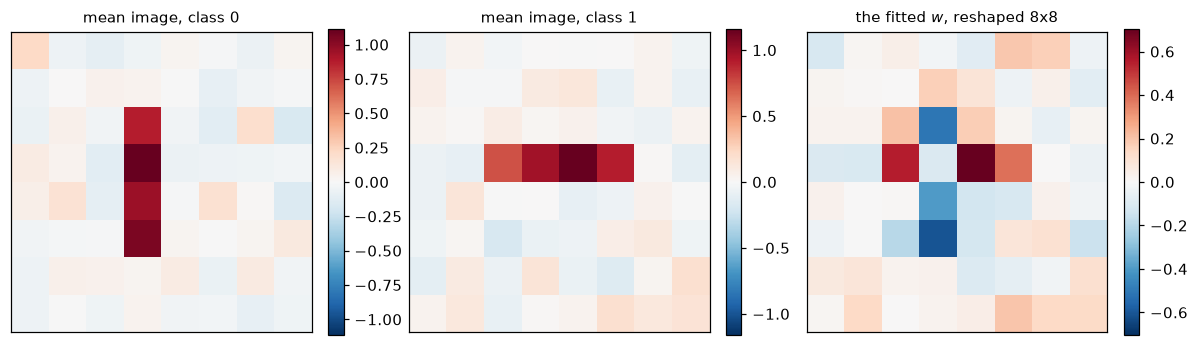

iterations                      : 114  (converged=True)
training accuracy               : 0.8100
cosine(w, template difference)  : 0.8607
largest |w| pixel               : (np.int64(3), np.int64(4))
the two template pixels are     : rows 2-5 col 3 (class 0), row 3 cols 2-5 (class 1)


In [11]:
side, n, noise = 8, 600, 1.5               # noise high enough that the classes overlap
tmpl_a, tmpl_b = np.zeros((side, side)), np.zeros((side, side))
tmpl_a[2:6, 3] = 1.0                       # a vertical bar
tmpl_b[3, 2:6] = 1.0                       # a horizontal bar

labels = (rng.random(n) < 0.5).astype(float)
images = np.array([(tmpl_b if y else tmpl_a) + noise * rng.normal(size=(side, side))
                   for y in labels])
X = images.reshape(n, side * side)

res, hist = run(SteepestDescent(), Armijo(), logistic_regression(X, labels),
                np.zeros(side * side), max_iter=800, tol=1e-6)
w_img = res.x.reshape(side, side)
truth = tmpl_b - tmpl_a                    # what w should be proportional to

fig, ax = plt.subplots(1, 3, figsize=(11, 3.4))
for a, (img, title) in zip(ax, [
    (images[labels == 0].mean(axis=0), "mean image, class 0"),
    (images[labels == 1].mean(axis=0), "mean image, class 1"),
    (w_img, "the fitted $w$, reshaped 8x8"),
], strict=True):
    lim = np.abs(img).max()
    im = a.imshow(img, cmap="RdBu_r", vmin=-lim, vmax=lim)
    a.set_title(title), a.set_xticks([]), a.set_yticks([]), a.grid(False)
    fig.colorbar(im, ax=a, fraction=0.046)
fig.tight_layout()
plt.show()

flat_w, flat_t = w_img.ravel(), truth.ravel()
cos = float(flat_w @ flat_t / (np.linalg.norm(flat_w) * np.linalg.norm(flat_t)))
pred = (X @ res.x > 0).astype(float)
print(f"iterations                      : {res.iterations}  (converged={res.converged})")
print(f"training accuracy               : {np.mean(pred == labels):.4f}")
print(f"cosine(w, template difference)  : {cos:.4f}")
print(f"largest |w| pixel               : {np.unravel_index(np.abs(w_img).argmax(), w_img.shape)}")
print(f"the two template pixels are     : rows 2-5 col 3 (class 0), row 3 cols 2-5 (class 1)")

**A coefficient vector you can read.**

The third panel is the same numbers the optimizer has been printing, folded back into the
shape the data came in: blue where a bright pixel argues for class 0, red for class 1. It
reproduces the two bars, because that is the only thing separating the classes.

The printed cosine says how close that is in numbers. It is high but not $1$, and should
not be: the loss only sees $Xw$, so the scale of $w$ is free, and 600 heavily noised
samples carry some noise into it.

**Why this matters beyond the picture.** When a fit goes wrong, a coefficient vector is a
wall of numbers. Reshaped, it tells you immediately whether the model learned the signal or
an artefact - a border pixel, a scanner edge, the patient ID left in column 3. Look at your
parameters.

---

## Checkpoint

Everything from day 1 to day 2 should be green before you leave, and
`mypy --strict` must be clean. A red type check counts as a failure.

In [12]:
check("-m", "day1 or day2")

..........................................................               [100%]
58 passed, 179 deselected in 0.09s

PASSED


In [13]:
r = subprocess.run([sys.executable, "-m", "mypy"], cwd=OPTLAB,
                   capture_output=True, text=True)
print(r.stdout.strip() or r.stderr.strip())

src/optlab/problems/glm.py:42: error: Returning Any from function declared to return "ndarray[tuple[Any, ...], dtype[float64]]"  [no-any-return]
src/optlab/optimizers/descent.py:41: error: "self" parameter missing for a non-static method (or an invalid type for self)  [misc]
Found 2 errors in 2 files (checked 30 source files)


---

## Before you leave

1. Why does the zigzag appear, and what makes consecutive steps orthogonal?
2. What exactly does $(\kappa-1)/(\kappa+1)$ predict, and for which step size?
3. Why can Armijo beat the best constant step?
4. Where is the true stability boundary for a fixed step, and what happens between $1/L$
   and $2/L$?
5. Why is `alpha <= 1/M` safe, and where does the `2` in `2/M` come from?
6. Which of your classes would have to change to add a new direction rule? *(None. That is
   the answer, and it is the point.)*
7. What did you change inside `DescentOptimizer` to produce any figure here? *(Nothing.)*

---

## Before the debrief

Be able to answer:

1. Why is `alpha <= 1/M` safe - and where exactly does the `2` in `2/M` come from?
2. Why does momentum help? Answer in terms of what happens to the oscillating components
   versus the drift along the valley floor.
3. Which of your classes would have to change to add a new direction rule? (Correct
   answer: none.)